In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

ПР4:

In [17]:
df = pd.read_csv('titanic.csv')

features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

data = df[features + [target]].copy()

print("=== Пропущенные значения до обработки ===")
print(data.isnull().sum())

=== Пропущенные значения до обработки ===
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


In [18]:
# Преобразование Sex в числовой
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

print("\n=== Проверка подготовленных данных ===")
print(data.info())
print(data.isnull().sum())
print(data.head())


=== Проверка подготовленных данных ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Age       714 non-null    float64
 2   Sex       891 non-null    int64  
 3   Fare      891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Survived  891 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 48.9 KB
None
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [20]:
corr_matrix = data.corr()
corr_rounded = corr_matrix.round(2)
print("\n=== Корреляционная матрица ===")
print(corr_rounded)


=== Корреляционная матрица ===
          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.37 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.37  1.00 -0.09  0.10  -0.31  -0.19     -0.08
Sex        -0.13 -0.09  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.31  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.19  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.08  0.54  0.26  -0.04   0.08      1.00


In [21]:
# Анализ корреляции
survived_corr = corr_rounded['Survived'].drop('Survived')
print("\n=== Корреляция с Survived ===")
print(survived_corr.sort_values(ascending=False))


=== Корреляция с Survived ===
Sex       0.54
Fare      0.26
Parch     0.08
SibSp    -0.04
Age      -0.08
Pclass   -0.34
Name: Survived, dtype: float64


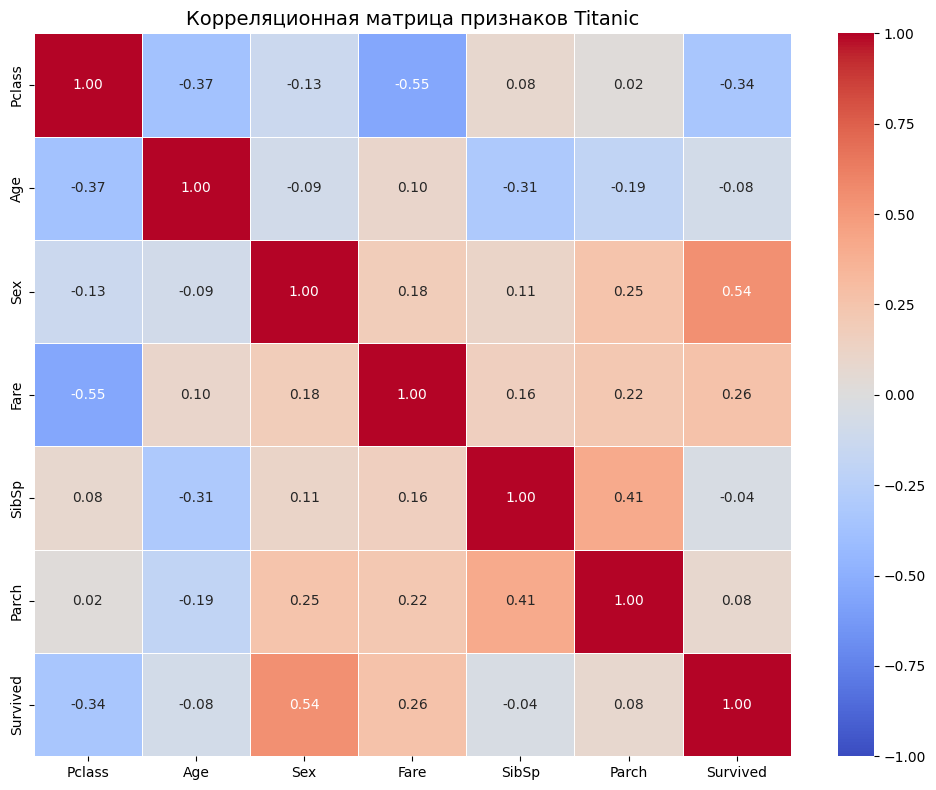

In [22]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1, vmax=1
)
plt.title('Корреляционная матрица признаков Titanic', fontsize=14)
plt.tight_layout()
plt.show()

ПР5:

In [23]:
print("\n=== ВЫВОДЫ ПО КОРРЕЛЯЦИИ ===")
print("Наиболее полезные признаки для предсказания Survived:")
print("  Sex (0.54) - самый сильный предиктор: женщины выживали чаще")
print("  Pclass (-0.34) - пассажиры 1-го класса выживали чаще")
print("  Fare (0.26) - косвенно связан с классом: чем дороже билет, тем выше шансы")
print("  Age (-0.06), SibSp (-0.04), Parch (0.08) - слабая линейная связь")
print("\nМожно ли выбирать признаки только на основании корреляции?")
print("  Нет, нельзя. Причины:")
print("  - Разный масштаб: корреляция не учитывает масштаб и распределение признаков")
print("  - Только линейная связь: коэффициент Пирсона улавливает лишь линейные зависимости,")
print("    нелинейные останутся незамеченными")


=== ВЫВОДЫ ПО КОРРЕЛЯЦИИ ===
Наиболее полезные признаки для предсказания Survived:
  Sex (0.54) - самый сильный предиктор: женщины выживали чаще
  Pclass (-0.34) - пассажиры 1-го класса выживали чаще
  Fare (0.26) - косвенно связан с классом: чем дороже билет, тем выше шансы
  Age (-0.06), SibSp (-0.04), Parch (0.08) - слабая линейная связь

Можно ли выбирать признаки только на основании корреляции?
  Нет, нельзя. Причины:
  - Разный масштаб: корреляция не учитывает масштаб и распределение признаков
  - Только линейная связь: коэффициент Пирсона улавливает лишь линейные зависимости,
    нелинейные останутся незамеченными


ПР6

In [24]:
y = df["Survived"]
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()

print("\n=== X (первые 5 строк) ===")
print(X.head())
print("\nПропуски в X:")
print(X.isnull().sum())



=== X (первые 5 строк) ===
   Pclass   Age     Sex     Fare  SibSp  Parch
0       3  22.0    male   7.2500      1      0
1       1  38.0  female  71.2833      1      0
2       3  26.0  female   7.9250      0      0
3       1  35.0  female  53.1000      1      0
4       3  35.0    male   8.0500      0      0

Пропуски в X:
Pclass      0
Age       177
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64


In [25]:
# Обработка пропусков
X["Age"] = X["Age"].fillna(X["Age"].median())

In [27]:
# Преобразование Sex
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print("\n=== X после обработки ===")
print(X.info())
print(X.isnull().sum())



=== X после обработки ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  891 non-null    int64  
 1   Age     891 non-null    float64
 2   Sex     0 non-null      float64
 3   Fare    891 non-null    float64
 4   SibSp   891 non-null    int64  
 5   Parch   891 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 41.9 KB
None
Pclass      0
Age         0
Sex       891
Fare        0
SibSp       0
Parch       0
dtype: int64


In [28]:
# Разделение
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n=== Размеры наборов ===")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)


=== Размеры наборов ===
X_train: (712, 6)
X_test:  (179, 6)
y_train: (712,)
y_test:  (179,)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.13/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

df = pd.read_csv('titanic.csv')

y = df['Survived']
X = df[['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']].copy()

X['Age'] = X['Age'].fillna(X['Age'].median())

if X['Sex'].dtype == 'object' or X['Sex'].dtype.name == 'category':
    X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
else:
    X['Sex'] = X['Sex'].astype(int)

print(X.isnull().sum())
print("Всего NaN:", X.isnull().sum().sum())
print(X.dtypes)
print(X.head())

if X.isnull().sum().sum() > 0:
    mask = X.notna().all(axis=1)
    X = X[mask]
    y = y[mask]
    print("Осталось строк:", len(X))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("NaN в X_train_scaled:", pd.isna(X_train_scaled).sum())
print("NaN в X_test_scaled: ", pd.isna(X_test_scaled).sum())

print("\n=== ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ ===")
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:  ", y_test.iloc[:10].to_list())

print("\nAccuracy :", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall   :", round(recall_score(y_test, y_pred_lr), 4))
print("F1       :", round(f1_score(y_test, y_pred_lr), 4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64
Всего NaN: 0
Pclass      int64
Age       float64
Sex         int64
Fare      float64
SibSp       int64
Parch       int64
dtype: object
   Pclass   Age  Sex     Fare  SibSp  Parch
0       3  22.0    0   7.2500      1      0
1       1  38.0    1  71.2833      1      0
2       3  26.0    1   7.9250      0      0
3       1  35.0    1  53.1000      1      0
4       3  35.0    0   8.0500      0      0
NaN в X_train_scaled: 0
NaN в X_test_scaled:  0

=== ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ ===
Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы:   [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

Accuracy : 0.8045
Precision: 0.7656
Recall   : 0.7101
F1       : 0.7368
Confusion matrix:
 [[95 15]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro av

In [37]:
print("\n=== ДЕРЕВО РЕШЕНИЙ ===")
model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tree), 4))
print("F1       :", round(f1_score(y_test, y_pred_tree), 4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))


=== ДЕРЕВО РЕШЕНИЙ ===
Accuracy дерева: 0.7821
Precision: 0.875
Recall   : 0.5072
F1       : 0.6422
Confusion matrix:
 [[105   5]
 [ 34  35]]
              precision    recall  f1-score   support

           0       0.76      0.95      0.84       110
           1       0.88      0.51      0.64        69

    accuracy                           0.78       179
   macro avg       0.82      0.73      0.74       179
weighted avg       0.80      0.78      0.77       179



In [39]:
print("\n=== ДЕРЕВО РЕШЕНИЙ ===")
model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tree), 4))
print("F1       :", round(f1_score(y_test, y_pred_tree), 4))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_tree))


=== ДЕРЕВО РЕШЕНИЙ ===
Accuracy дерева: 0.7821
Precision: 0.875
Recall   : 0.5072
F1       : 0.6422
Confusion matrix:
 [[105   5]
 [ 34  35]]
